## Step 9: Save and Store Region Data

**What happens here**: Save extracted regions in multiple formats for later processing:
- JSON (portable, human-readable)
- Pickle (Python-specific, preserves all data types)
- Individual mask images (PNG)
- Labeled segmentation array (NPY)
- Colored visualization (PNG)

**Output**: Structured data files in the OUTPUT_DIR ready for downstream tasks

In [ ]:
# Step 9: Final Summary Visualization
fig, axes = plt.subplots(2, 2, figsize=(18, 16))

# Top-left: Original RGB
axes[0, 0].imshow(rgb_img)
axes[0, 0].set_title('Input: Original RGB Image', fontsize=13, fontweight='bold')
axes[0, 0].axis('off')

# Top-right: Canny edges
axes[0, 1].imshow(canny_binary, cmap='gray')
axes[0, 1].set_title('Input: Canny Edge Detection', fontsize=13, fontweight='bold')
axes[0, 1].axis('off')

# Bottom-left: Distance transform
im = axes[1, 0].imshow(dist_transform, cmap='jet')
axes[1, 0].set_title('Intermediate: Distance Transform', fontsize=13, fontweight='bold')
axes[1, 0].axis('off')
plt.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

# Bottom-right: Final segmentation
axes[1, 1].imshow(segmentation_colored)
axes[1, 1].set_title(f'Output: Final Segmentation\\n({len(regions_data)} regions)', 
                    fontsize=13, fontweight='bold')
axes[1, 1].axis('off')

plt.suptitle('Watershed Segmentation Pipeline Summary', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# Print final summary
print("\\n" + "=" * 60)
print("WATERSHED SEGMENTATION COMPLETE")
print("=" * 60)
print(f"Image: {test_image_name}")
print(f"Image size: {width} x {height} pixels")
print(f"Total regions found: {len(regions_data)}")
print(f"Area threshold: {area_threshold} pixels")
print(f"\\nRegion Summary:")
for region in regions_data:
    print(f"  Region {region['label']}: {region['area']:,} pixels ({region['percentage']:.1f}% of image)")

print(f"\\nAll results saved to: {watershed_output_dir}")
print(f"\\n✓ Pipeline completed successfully!")

In [ ]:
# Step 9: Save and store region data
print("Step 9: Save and Store Region Data")
print("=" * 50)

import json
import pickle

# Create subdirectory for this image's watershed results
watershed_output_dir = os.path.join(OUTPUT_DIR, f"{test_image_name}_watershed")
os.makedirs(watershed_output_dir, exist_ok=True)
print(f"Output directory: {watershed_output_dir}\n")

# 1. Save as JSON (portable format)
regions_json = []
for region in regions_data:
    region_json = {
        'label': int(region['label']),
        'area': int(region['area']),
        'percentage': float(region['percentage']),
        'bounding_box': {
            'x': int(region['bounding_box'][0]),
            'y': int(region['bounding_box'][1]),
            'width': int(region['bounding_box'][2]),
            'height': int(region['bounding_box'][3])
        },
        'centroid': {
            'x': int(region['centroid'][0]),
            'y': int(region['centroid'][1])
        },
        'contour_points': region['contour'].tolist() if region['contour'] is not None else []
    }
    regions_json.append(region_json)

json_path = os.path.join(watershed_output_dir, 'regions_data.json')
with open(json_path, 'w') as f:
    json.dump(regions_json, f, indent=2)
print(f"✓ Saved JSON: {json_path}")

# 2. Save as Pickle (preserves all Python objects)
pickle_path = os.path.join(watershed_output_dir, 'regions_data.pkl')
with open(pickle_path, 'wb') as f:
    pickle.dump(regions_data, f)
print(f"✓ Saved Pickle: {pickle_path}")

# 3. Save individual region masks as PNG
masks_dir = os.path.join(watershed_output_dir, 'masks')
os.makedirs(masks_dir, exist_ok=True)
for region in regions_data:
    mask_path = os.path.join(masks_dir, f"region_{region['label']:02d}_mask.png")
    cv2.imwrite(mask_path, region['mask'])
print(f"✓ Saved {len(regions_data)} individual masks to: {masks_dir}")

# 4. Save labeled segmentation array (NPY)
segmentation_npy_path = os.path.join(watershed_output_dir, 'segmentation_labels.npy')
np.save(segmentation_npy_path, final_segmentation_consecutive)
print(f"✓ Saved segmentation array: {segmentation_npy_path}")

# 5. Save colored visualization
segmentation_colored = np.zeros((*final_segmentation_consecutive.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in range(1, final_segmentation_consecutive.max() + 1):
    color = np.random.randint(50, 255, 3, dtype=np.uint8)
    segmentation_colored[final_segmentation_consecutive == label] = color

colored_path = os.path.join(watershed_output_dir, 'segmentation_colored.png')
cv2.imwrite(colored_path, cv2.cvtColor(segmentation_colored, cv2.COLOR_RGB2BGR))
print(f"✓ Saved colored segmentation: {colored_path}")

# 6. Save summary report
summary_path = os.path.join(watershed_output_dir, 'summary.txt')
with open(summary_path, 'w') as f:
    f.write(f"Watershed Segmentation Summary\\n")
    f.write(f"=" * 50 + "\\n")
    f.write(f"Image: {test_image_name}\\n")
    f.write(f"Image size: {width} x {height} pixels\\n")
    f.write(f"Total regions: {len(regions_data)}\\n")
    f.write(f"Area threshold: {area_threshold} pixels\\n\\n")
    
    f.write(f"Region Details:\\n")
    f.write(f"-" * 50 + "\\n")
    for region in regions_data:
        f.write(f"Region {region['label']}:\\n")
        f.write(f"  Area: {region['area']:,} pixels ({region['percentage']:.2f}%)\\n")
        f.write(f"  Bounding box: {region['bounding_box']}\\n")
        f.write(f"  Centroid: {region['centroid']}\\n\\n")

print(f"✓ Saved summary report: {summary_path}")

print(f"\\n✓ All data saved successfully to:\\n  {watershed_output_dir}")

## Step 8: Extract Individual Shapes and Properties

**What happens here**: Create individual masks for each region and extract properties:
- Binary mask for each region
- Area (pixel count)
- Contours (boundary coordinates)
- Bounding box (x, y, width, height)
- Centroid (center point)

**Output**: Dictionary with all region properties for each labeled region

In [ ]:
# Step 8: Extract individual shapes and properties
print("Step 8: Extract Individual Shapes and Properties")
print("=" * 50)

regions_data = []

for label in range(1, final_segmentation_consecutive.max() + 1):
    # Binary mask for this region
    region_mask = (final_segmentation_consecutive == label).astype(np.uint8) * 255
    
    # Calculate area
    area = np.count_nonzero(region_mask)
    
    # Find contours
    contours, _ = cv2.findContours(region_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    main_contour = contours[0] if len(contours) > 0 else None
    
    # Bounding box
    if main_contour is not None:
        x, y, w, h = cv2.boundingRect(main_contour)
    else:
        y_coords, x_coords = np.where(region_mask > 0)
        x, y = x_coords.min(), y_coords.min()
        w, h = x_coords.max() - x + 1, y_coords.max() - y + 1
    
    # Calculate centroid using image moments
    M = cv2.moments(region_mask)
    if M['m00'] != 0:
        cx = int(M['m10'] / M['m00'])
        cy = int(M['m01'] / M['m00'])
    else:
        cx, cy = x + w//2, y + h//2
    
    # Store data
    region_info = {
        'label': label,
        'mask': region_mask,
        'contour': main_contour,
        'area': area,
        'bounding_box': (x, y, w, h),
        'centroid': (cx, cy),
        'percentage': (area / total_pixels) * 100
    }
    regions_data.append(region_info)
    
    print(f"Region {label}:")
    print(f"  Area: {area:,} pixels ({region_info['percentage']:.2f}%)")
    print(f"  Bounding box: ({x}, {y}, {w}, {h})")
    print(f"  Centroid: ({cx}, {cy})")

print(f"\n✓ Extracted {len(regions_data)} regions with all properties!")
print("  Each region has: mask, contour, area, bbox, centroid")

In [ ]:
# Step 8: Visualization
# Calculate grid size for individual masks
n_regions = len(regions_data)
n_cols = min(4, n_regions)
n_rows = (n_regions + n_cols - 1) // n_cols

fig = plt.figure(figsize=(20, max(12, n_rows * 3)))
gs = fig.add_gridspec(3 + n_rows, 3, hspace=0.4, wspace=0.3)

# Row 1: Original with contours
ax1 = fig.add_subplot(gs[0, :])
result_contours = rgb_img.copy()
for i, region in enumerate(regions_data):
    color = tuple(np.random.randint(100, 255, 3).tolist())
    if region['contour'] is not None:
        cv2.drawContours(result_contours, [region['contour']], -1, color, 2)
ax1.imshow(result_contours)
ax1.set_title('Original with All Region Contours', fontsize=14, fontweight='bold')
ax1.axis('off')

# Row 2: Bounding boxes and centroids
ax2 = fig.add_subplot(gs[1, 0])
result_bbox = rgb_img.copy()
for region in regions_data:
    x, y, w, h = region['bounding_box']
    cv2.rectangle(result_bbox, (x, y), (x+w, y+h), (0, 255, 0), 2)
    cv2.putText(result_bbox, f"R{region['label']}", (x, y-5), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
ax2.imshow(result_bbox)
ax2.set_title('Bounding Boxes', fontsize=12, fontweight='bold')
ax2.axis('off')

ax3 = fig.add_subplot(gs[1, 1])
result_centroids = rgb_img.copy()
for region in regions_data:
    cx, cy = region['centroid']
    cv2.circle(result_centroids, (cx, cy), 8, (255, 0, 0), -1)
    cv2.putText(result_centroids, f"{region['label']}", (cx+12, cy), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
ax3.imshow(result_centroids)
ax3.set_title('Centroids', fontsize=12, fontweight='bold')
ax3.axis('off')

# Statistics table
ax4 = fig.add_subplot(gs[1, 2])
ax4.axis('off')
table_data = [['ID', 'Area', '% of Image']]
for region in regions_data:
    table_data.append([
        f"R{region['label']}",
        f"{region['area']:,}",
        f"{region['percentage']:.1f}%"
    ])
table = ax4.table(cellText=table_data, cellLoc='center', loc='center',
                 colWidths=[0.2, 0.4, 0.4])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)
# Header row styling
for i in range(3):
    table[(0, i)].set_facecolor('#4CAF50')
    table[(0, i)].set_text_props(weight='bold', color='white')
ax4.set_title('Region Statistics', fontsize=12, fontweight='bold')

# Individual region masks
for idx, region in enumerate(regions_data):
    row = 3 + idx // n_cols
    col = idx % n_cols
    ax = fig.add_subplot(gs[row, col])
    ax.imshow(region['mask'], cmap='gray')
    ax.set_title(f"Region {region['label']} Mask\n({region['area']:,} px)", 
                fontsize=10, fontweight='bold')
    ax.axis('off')

plt.show()

print("✓ Check: Contours should outline each region cleanly")
print("✓ Check: Bounding boxes should fit tightly around regions")
print("✓ Check: Centroids should be inside their respective regions")
print("✓ Check: Individual masks should be clean binary images")

## Step 7: Extract and Filter Regions

**What happens here**: Extract individual regions, calculate their areas, and filter out small regions below threshold.

**Process**:
1. Remove boundaries (-1) and background (1)
2. Calculate area for each region
3. Filter by minimum area threshold
4. Renumber labels consecutively

**Result**: Clean segmentation with only significant regions

In [ ]:
# Step 7: Extract and filter regions
print("Step 7: Extract and Filter Regions")
print("=" * 50)

# Extract regions (ignore background=1 and boundaries=-1)
regions_only = markers_with_bg.copy()
regions_only[regions_only == -1] = 0  # Remove boundaries
regions_only[regions_only == 1] = 0   # Remove background

# Calculate area for each region
unique_labels, label_counts = np.unique(regions_only[regions_only > 0], return_counts=True)

print(f"Before filtering:")
print(f"  Total regions: {len(unique_labels)}")
print(f"  Region areas range: {label_counts.min():,} to {label_counts.max():,} pixels")

# Filter by area threshold
area_threshold = MIN_REGION_AREA  # Using the global parameter
filtered_labels = []
region_areas_dict = {}

for label, count in zip(unique_labels, label_counts):
    region_areas_dict[label] = count
    if count >= area_threshold:
        filtered_labels.append(label)

print(f"\nAfter filtering (threshold = {area_threshold} pixels):")
print(f"  Regions kept: {len(filtered_labels)}")
print(f"  Regions removed: {len(unique_labels) - len(filtered_labels)}")

# Create final segmentation
final_segmentation = np.zeros_like(regions_only)
for label in filtered_labels:
    final_segmentation[regions_only == label] = label

# Renumber consecutively (1, 2, 3, ...)
final_segmentation_consecutive = np.zeros_like(final_segmentation)
for new_label, old_label in enumerate(filtered_labels, start=1):
    final_segmentation_consecutive[final_segmentation == old_label] = new_label

print(f"\n✓ Final segmentation created!")
print(f"  Labels: 1 to {len(filtered_labels)}")
print(f"  Background: 0")

# Calculate final statistics
for new_label, old_label in enumerate(filtered_labels, start=1):
    area = region_areas_dict[old_label]
    percentage = (area / total_pixels) * 100
    print(f"  Region {new_label}: {area:,} pixels ({percentage:.2f}% of image)")

In [ ]:
# Step 7: Visualization
fig = plt.figure(figsize=(20, 12))

# Create 2x3 grid
gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.2)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, :2])
ax5 = fig.add_subplot(gs[1, 2])

# 1. Original RGB
ax1.imshow(rgb_img)
ax1.set_title('Original Image', fontsize=12, fontweight='bold')
ax1.axis('off')

# 2. All regions before filtering (colored)
regions_before_vis = np.zeros((*regions_only.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in np.unique(regions_only):
    if label > 0:
        color = np.random.randint(50, 255, 3, dtype=np.uint8)
        regions_before_vis[regions_only == label] = color
ax2.imshow(regions_before_vis)
ax2.set_title(f'All Regions Before Filtering\n({len(unique_labels)} regions)', fontsize=12, fontweight='bold')
ax2.axis('off')

# 3. Histogram of region sizes
ax3.bar(range(len(label_counts)), sorted(label_counts, reverse=True))
ax3.axhline(y=area_threshold, color='r', linestyle='--', label=f'Threshold = {area_threshold}')
ax3.set_xlabel('Region (sorted by size)', fontsize=10)
ax3.set_ylabel('Area (pixels)', fontsize=10)
ax3.set_title('Region Size Distribution', fontsize=12, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Final segmentation (colored overlay)
final_vis = np.zeros((*final_segmentation_consecutive.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in range(1, final_segmentation_consecutive.max() + 1):
    color = np.random.randint(50, 255, 3, dtype=np.uint8)
    final_vis[final_segmentation_consecutive == label] = color

# Blend with original
overlay = (rgb_img * 0.4 + final_vis * 0.6).astype(np.uint8)
ax4.imshow(overlay)
ax4.set_title(f'Final Segmentation After Filtering\n({len(filtered_labels)} regions, threshold={area_threshold})', 
             fontsize=12, fontweight='bold')
ax4.axis('off')

# 5. Final segmentation (solid colors)
ax5.imshow(final_vis)
ax5.set_title('Final Regions\n(Solid colors)', fontsize=12, fontweight='bold')
ax5.axis('off')

plt.show()

print("✓ Check: Small noise regions should be removed")
print("✓ Check: Major objects should have their own regions")
print(f"✓ Final region count: {len(filtered_labels)}")

## Step 6: Apply Watershed Algorithm

**What happens here**: The core watershed flooding! Floods from all markers simultaneously on the original RGB image. Boundaries form where different floods meet.

**Watershed behavior**:
- Modifies markers in-place
- Boundaries marked with -1
- Each region keeps its marker label
- Background remains 1

**Result**: Segmented image with clear boundaries between regions

In [ ]:
# Step 6: Apply watershed algorithm
print("Step 6: Apply Watershed Algorithm")
print("=" * 50)

# Make a copy for visualization (watershed modifies in-place)
markers_before_watershed = markers_with_bg.copy()

# Apply watershed (requires RGB image)
# This modifies markers_with_bg in-place
print("Running watershed... ", end='')
cv2.watershed(rgb_img, markers_with_bg)
print("Done!")

# Count different label types
num_boundaries = np.sum(markers_with_bg == -1)
num_background = np.sum(markers_with_bg == 1)
region_labels = np.unique(markers_with_bg[markers_with_bg > 1])
num_regions = len(region_labels)

print(f"\nWatershed results:")
print(f"  Boundary pixels (-1): {num_boundaries:,}")
print(f"  Background pixels (1): {num_background:,}")
print(f"  Number of regions: {num_regions}")
print(f"  Region labels: {region_labels[:10]}{'...' if len(region_labels) > 10 else ''}")

# Create visualization with red boundaries
result_with_boundaries = rgb_img.copy()
result_with_boundaries[markers_with_bg == -1] = [255, 0, 0]  # Red boundaries

print("\n✓ Watershed segmentation complete!")
print("  Boundaries marked in red")

In [ ]:
# Step 6: Visualization
fig, axes = plt.subplots(2, 2, figsize=(18, 18))

# Top-left: Original RGB
axes[0, 0].imshow(rgb_img)
axes[0, 0].set_title('Original RGB Image', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')

# Top-right: Markers before watershed (colored)
markers_before_vis = np.zeros((*markers_before_watershed.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in np.unique(markers_before_watershed):
    if label > 0:
        color = np.random.randint(50, 255, 3, dtype=np.uint8)
        markers_before_vis[markers_before_watershed == label] = color
axes[0, 1].imshow(markers_before_vis)
axes[0, 1].set_title('Markers Before Watershed', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')

# Bottom-left: Markers after watershed (colored, with boundaries)
markers_after_vis = np.zeros((*markers_with_bg.shape, 3), dtype=np.uint8)
np.random.seed(42)
for label in np.unique(markers_with_bg):
    if label == -1:
        markers_after_vis[markers_with_bg == -1] = [255, 0, 0]  # Red boundaries
    elif label > 0:
        color = np.random.randint(50, 255, 3, dtype=np.uint8)
        markers_after_vis[markers_with_bg == label] = color
axes[1, 0].imshow(markers_after_vis)
axes[1, 0].set_title('Markers After Watershed\n(Red = boundaries)', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')

# Bottom-right: Result with red boundaries overlaid
axes[1, 1].imshow(result_with_boundaries)
axes[1, 1].set_title('Segmentation Result\n(Red lines = region boundaries)', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

print("✓ Check: Red boundaries should separate regions")
print("✓ Check: Boundaries should roughly align with Canny edges")
print("✓ Check: Boundaries should be continuous lines")
print(f"✓ Number of regions found: {num_regions}")

## Step 5: Add Background Marker

**What happens here**: Adds a background marker to prevent watershed from merging everything. The background acts as a reference point and keeps regions separate.

**Strategy**: Set border pixels to label=1 (background), then increment all other markers by 1 to avoid conflicts.

**Required format**: Markers must be int32 type for cv2.watershed().

In [ ]:
# Step 5: Add background marker
print("Step 5: Add Background Marker")
print("=" * 50)

# Create copy of markers
markers_with_bg = markers.copy()

# Get image dimensions
height, width = markers.shape
border_thickness = 10

print(f"Image size: {width} x {height}")
print(f"Border thickness: {border_thickness} pixels")

# First, increment all existing markers by 1 to make room for background=1
markers_with_bg[markers_with_bg > 0] += 1

# Set border pixels to 1 (background marker)
markers_with_bg[0:border_thickness, :] = 1  # Top
markers_with_bg[height-border_thickness:height, :] = 1  # Bottom
markers_with_bg[:, 0:border_thickness] = 1  # Left
markers_with_bg[:, width-border_thickness:width] = 1  # Right

# Convert to int32 (required by watershed)
markers_with_bg = markers_with_bg.astype(np.int32)

print(f"\n✓ Background marker added")
print(f"  Background label = 1")
print(f"  Region markers now range from 2 to {markers_with_bg.max()}")
print(f"  Data type: {markers_with_bg.dtype} (required for watershed)")

# Count pixels per label
unique_after, counts_after = np.unique(markers_with_bg, return_counts=True)
bg_pixels = counts_after[unique_after == 1][0] if 1 in unique_after else 0
print(f"  Background pixels: {bg_pixels:,}")

print("\n✓ Markers prepared for watershed!")

In [ ]:
# Step 5: Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Create colored visualizations
markers_vis_before = np.zeros((*markers.shape, 3), dtype=np.uint8)
markers_vis_after = np.zeros((*markers_with_bg.shape, 3), dtype=np.uint8)

np.random.seed(42)  # For consistent colors
for label in np.unique(markers):
    if label > 0:
        color = np.random.randint(50, 255, 3, dtype=np.uint8)
        markers_vis_before[markers == label] = color

np.random.seed(42)  # Reset for similar colors
for label in np.unique(markers_with_bg):
    if label == 1:
        # Background = blue
        markers_vis_after[markers_with_bg == 1] = [100, 100, 255]
    elif label > 1:
        color = np.random.randint(50, 255, 3, dtype=np.uint8)
        markers_vis_after[markers_with_bg == label] = color

axes[0].imshow(markers_vis_before)
axes[0].set_title('Original Markers\n(Without background)', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(markers_vis_after)
axes[1].set_title('Markers with Background\n(Blue border = background marker)', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("✓ Check: Blue border should be visible around image edges")
print("✓ Check: Interior markers should have different colors")
print("✓ Check: No overlap between background and region markers")

## Step 4: Find Markers (Local Maxima)

**What happens here**: Identify peaks in the distance transform to use as watershed markers (flooding sources). Each peak represents one region center.

**Thresholding strategy**: Keep only pixels with distance above a threshold (e.g., 50% of maximum distance). These high-distance pixels are at region centers.

**Labeling**: Use connected components to assign a unique label to each disconnected peak region.

In [ ]:
# Step 4: Find markers (local maxima)
print("Step 4: Find Markers (Local Maxima)")
print("=" * 50)

# Threshold to find peaks (adjust this ratio to control marker count)
threshold_ratio = 0.5  # Keep pixels with distance > 50% of max
max_distance = dist_transform.max()
threshold_value = threshold_ratio * max_distance

print(f"Max distance: {max_distance:.2f}")
print(f"Threshold ratio: {threshold_ratio}")
print(f"Threshold value: {threshold_value:.2f}")

# Create binary mask of peaks
_, peak_mask = cv2.threshold(dist_transform, threshold_value, 255, cv2.THRESH_BINARY)
peak_mask = np.uint8(peak_mask)

# Label each disconnected peak as unique marker
num_labels, markers = cv2.connectedComponents(peak_mask, connectivity=8)

# num_labels includes background (0), so actual markers = num_labels - 1
num_markers = num_labels - 1

print(f"\n✓ Found {num_markers} markers")
print(f"  Marker labels range from 1 to {num_markers}")
print(f"  Label 0 = background")

# Create colored visualization of markers
markers_colored = np.zeros((*markers.shape, 3), dtype=np.uint8)
for label in range(1, num_labels):
    # Assign random color to each marker
    color = np.random.randint(0, 255, 3, dtype=np.uint8)
    markers_colored[markers == label] = color

print("\n✓ Markers labeled successfully!")
print(f"  Tip: If too many markers, increase threshold_ratio (try 0.6-0.7)")
print(f"  Tip: If too few markers, decrease threshold_ratio (try 0.3-0.4)")

In [ ]:
# Step 4: Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 16))

# Top-left: Distance transform with colormap
im = axes[0, 0].imshow(dist_transform, cmap='jet')
axes[0, 0].set_title('Distance Transform\n(Showing Peak Locations)', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')
plt.colorbar(im, ax=axes[0, 0], fraction=0.046, pad=0.04)

# Top-right: Peak mask (binary)
axes[0, 1].imshow(peak_mask, cmap='gray')
axes[0, 1].set_title(f'Peak Mask (Binary)\n{num_markers} markers found', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')

# Bottom-left: Markers (labeled, colored)
axes[1, 0].imshow(markers_colored)
axes[1, 0].set_title('Markers (Labeled)\nEach color = unique marker', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')

# Bottom-right: Original with markers overlaid
overlay = rgb_img.copy()
overlay[peak_mask > 0] = [255, 0, 0]  # Red markers
axes[1, 1].imshow(overlay)
axes[1, 1].set_title('Original with Markers\n(Red dots = region centers)', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

print("✓ Check: Each major region should have at least one marker at its center")
print("✓ Check: Markers should be red dots on the original image")
print(f"✓ Current threshold ratio: {threshold_ratio} (adjust if needed)")

## Step 3: Compute Distance Transform

**What happens here**: Creates the "topographic landscape" by computing Euclidean distance from each white pixel to the nearest black (edge) pixel. Region centers become peaks, edges become valleys.

**Distance Transform**: For each white pixel, calculates the distance to the nearest black pixel:
- Pixels far from edges (region centers) = HIGH values (peaks)
- Pixels near edges = LOW values (slopes)
- Edge pixels = ZERO (valleys)

This creates a landscape perfect for watershed flooding!

In [ ]:
# Step 3: Compute distance transform
print("Step 3: Compute Distance Transform")
print("=" * 50)

# Compute distance transform (Euclidean distance)
dist_transform = cv2.distanceTransform(closed_edges, cv2.DIST_L2, 5)

print(f"Distance transform shape: {dist_transform.shape}")
print(f"Distance transform dtype: {dist_transform.dtype}")
print(f"Min distance: {dist_transform.min():.2f}")
print(f"Max distance: {dist_transform.max():.2f}")
print(f"Mean distance: {dist_transform.mean():.2f}")

# Normalize for visualization (0-255)
dist_normalized = cv2.normalize(dist_transform, None, 0, 255, cv2.NORM_MINMAX, cv2.CV_8U)

print(f"\nNormalized for visualization:")
print(f"  Range: {dist_normalized.min()} to {dist_normalized.max()}")

print("\n✓ Distance transform computed successfully!")
print("  Interpretation: Higher values = region centers (peaks)")
print("                  Lower values = near edges (slopes)")
print("                  Zero values = edge pixels (valleys)")

In [ ]:
# Step 3: Visualization
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(closed_edges, cmap='gray')
axes[0].set_title('Inverted Edges\n(Input)', fontsize=14, fontweight='bold')
axes[0].axis('off')

# Use JET colormap for topographic effect (red=high, blue=low)
im1 = axes[1].imshow(dist_transform, cmap='jet')
axes[1].set_title('Distance Transform (Raw)\n(Warm = Peaks, Cool = Valleys)', fontsize=14, fontweight='bold')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(dist_normalized, cmap='hot')
axes[2].set_title('Distance Transform (Normalized)\n(Bright = Peaks, Dark = Valleys)', fontsize=14, fontweight='bold')
axes[2].axis('off')
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print("✓ Check: Distance should be highest at region centers (bright/red areas)")
print("✓ Check: Distance should decrease towards edges (gradient)")
print("✓ Check: Edges should have zero distance (dark/blue areas)")

## Step 2: Invert the Edge Map

**What happens here**: Invert the Canny edge map so regions become white and edges become black. This is crucial because distance transform measures distance to the nearest BLACK pixel.

**Why invert**: Distance transform needs black pixels as reference points (barriers). After inversion:
- Regions between edges = WHITE (255) 
- Edges = BLACK (0)

**Optional**: Apply morphological closing to fill small gaps in edges.

In [ ]:
# Step 2: Invert the edge map
print("Step 2: Invert the Edge Map")
print("=" * 50)

# Invert using bitwise NOT
inverted_edges = cv2.bitwise_not(canny_binary)

print(f"Inverted edges shape: {inverted_edges.shape}")
print(f"Min value: {inverted_edges.min()}, Max value: {inverted_edges.max()}")

# Optional: Apply morphological closing to fill small gaps
close_gaps = True  # Set to False to skip closing
kernel_size = 3

if close_gaps:
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    closed_edges = cv2.morphologyEx(inverted_edges, cv2.MORPH_CLOSE, kernel, iterations=1)
    print(f"\n✓ Applied morphological closing with {kernel_size}x{kernel_size} kernel")
else:
    closed_edges = inverted_edges
    print("\n  Skipped morphological closing")

# Calculate statistics
num_white_pixels = np.count_nonzero(closed_edges)
white_percentage = (num_white_pixels / total_pixels) * 100

print(f"\nAfter inversion:")
print(f"  White (region) pixels: {num_white_pixels:,}")
print(f"  Black (edge) pixels: {total_pixels - num_white_pixels:,}")
print(f"  Region percentage: {white_percentage:.2f}%")
print("\n✓ Edge map inverted successfully!")

In [ ]:
# Step 2: Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(canny_binary, cmap='gray')
axes[0].set_title('Original Canny Edges\n(Edges = White)', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(closed_edges, cmap='gray')
axes[1].set_title('Inverted Edges (+ Closing)\n(Regions = White, Edges = Black)', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("✓ Check: Regions between edges should be white")
print("✓ Check: Edges should be black barriers")
print("✓ Check: If closing applied, small gaps should be filled")

# Region Segmentation Comparison

This notebook compares 4 different OpenCV-based approaches for segmenting images into distinct regions using Canny edge detection.

**Goal**: Segment hotel room images into distinct shapes/regions (bed, window, walls, floor) and filter out small regions below a threshold.

**Approaches**: All use OpenCV functions exclusively, comparing methods that use grayscale images vs. methods that rely on Canny edge maps.

## 1. Setup & Configuration

In [16]:
# Path configurations - UPDATE THESE
INPUT_IMAGES_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images"
RGBX_OUTPUTS_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output"
OUTPUT_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/region_segmentation"

# Segmentation parameters
MIN_REGION_AREA = 100  # Minimum pixels for a region to be kept

print(f"Input images: {INPUT_IMAGES_DIR}")
print(f"RGB->X outputs: {RGBX_OUTPUTS_DIR}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Min region area threshold: {MIN_REGION_AREA} pixels")

Input images: /Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images
RGB->X outputs: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output
Output directory: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/region_segmentation
Min region area threshold: 100 pixels


## 2. Import Dependencies

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from PIL import Image
import os
from pathlib import Path
import glob
import time

# Create output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("All dependencies imported successfully!")

All dependencies imported successfully!


## 3. File Management Helper

In [3]:
def create_dict(image_name, base_dir=RGBX_OUTPUTS_DIR):
    """
    Create a dictionary of file paths for a given image name.
    
    Args:
        image_name: Name of the image (without extension)
        base_dir: Base directory containing image outputs
    
    Returns:
        dict: Mapping of file types to their paths
    """
    img_suffix = {
        "input": "",
        "irr_npy": "_irradiance",
        "irr_exr": "_irradiance_linear",
        "irr_img": "_irradiance_preview",
        "nor_npy": "_normal",
        "nor_img": "_normal_preview",
        "wall_npy": "_wall_confidence",
        "wall_img": "_wall_confidence_viz",
    }
    
    def search_file(pattern, directory):
        matches = glob.glob(os.path.join(directory, pattern))
        if matches: 
            return Path(matches[0])
        return None
    
    item = {}
    directory = f"{base_dir}/{image_name}"
    
    if not os.path.exists(directory):
        print(f"Warning: Directory not found: {directory}")
        return None
    
    for suffix in img_suffix.keys():
        item[suffix] = search_file(f"{image_name}{img_suffix[suffix]}.*", directory)
    
    return item

print("File management helper created!")

File management helper created!


## 4. Edge Detection Function

In [4]:
def canny_detect(img_path, use_grayscale=True, blur_size=(5, 5), 
                low_threshold=50, high_threshold=150):
    """
    Apply Canny edge detection with optional grayscale conversion.
    
    Args:
        img_path: Path to image file or numpy array
        use_grayscale: Whether to convert to grayscale before edge detection
        blur_size: Gaussian blur kernel size (width, height)
        low_threshold: Lower threshold for Canny
        high_threshold: Upper threshold for Canny
    
    Returns:
        numpy.ndarray: Binary edge map (H, W) with values 0 or 255
    """
    # Load image if it's a path
    if isinstance(img_path, (str, Path)):
        img = cv2.imread(str(img_path))
        if img is None:
            raise ValueError(f"Could not load image from path: {img_path}")
    else:
        img = img_path
    
    # Convert to grayscale if requested
    if use_grayscale and len(img.shape) == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Apply Gaussian blur
    blurred = cv2.GaussianBlur(img, blur_size, 0)
    
    # Apply Canny edge detection
    edges = cv2.Canny(blurred, low_threshold, high_threshold)
    
    return edges

print("Edge detection function created!")
print("Usage: edges = canny_detect(image_path, use_grayscale=True)")

Edge detection function created!
Usage: edges = canny_detect(image_path, use_grayscale=True)


## 5. Core Segmentation Functions

These are the 4 approaches we'll compare. Each takes a grayscale image and/or edge map and returns labeled regions.

In [5]:
def segment_regions_approach_1(grayscale_img, edge_map, min_area_threshold,
                              seed_spacing=25, intensity_tolerance=15):
    """
    Approach 1: Grayscale Image Only Based Flood Fill

    Segments based on intensity similarity without using edge information.
    Grows regions from seed points by including neighbors within tolerance.

    Args:
        grayscale_img: (H, W) grayscale image array
        edge_map: (H, W) binary edge map from Canny (not used in this approach)
        min_area_threshold: Minimum region area in pixels
        seed_spacing: Spacing between seed points in pixels (default: 25)
        intensity_tolerance: Tolerance for flood fill (default: 15)

    Returns:
        dict containing labeled_image, num_regions, region_stats, method_name
    """
    h, w = grayscale_img.shape

    # Create labeled image (0 = unlabeled)
    labeled = np.zeros((h, w), dtype=np.int32)

    # Create mask for flood fill (needs extra border)
    mask = np.zeros((h + 2, w + 2), dtype=np.uint8)

    # Generate seed points on a grid
    seeds = []
    for y in range(seed_spacing // 2, h, seed_spacing):
        for x in range(seed_spacing // 2, w, seed_spacing):
            seeds.append((x, y))

    current_label = 1

    # Perform flood fill from each seed
    for seed_x, seed_y in seeds:
        if labeled[seed_y, seed_x] == 0:  # Not yet labeled
            # Reset mask for this flood fill
            mask.fill(0)

            # Perform flood fill
            _, filled_img, _, _ = cv2.floodFill(
                grayscale_img.copy(),
                mask,
                (seed_x, seed_y),
                newVal=current_label,
                loDiff=intensity_tolerance,
                upDiff=intensity_tolerance,
                flags=cv2.FLOODFILL_FIXED_RANGE | (current_label << 8)
            )

            # Extract the filled region from mask (remove border)
            filled_mask = mask[1:-1, 1:-1]

            # Assign label to these pixels
            labeled[filled_mask > 0] = current_label
            current_label += 1

    # Use connected components to clean up the labeled image
    num_labels, labels_clean = cv2.connectedComponents(
        (labeled > 0).astype(np.uint8)
    )

    # Calculate region areas
    region_areas = np.bincount(labels_clean.flat)

    # Filter by area threshold
    valid_labels = np.where(region_areas >= min_area_threshold)[0]
    # Exclude background (label 0)
    valid_labels = valid_labels[valid_labels > 0]

    # Create filtered labeled image
    labeled_filtered = np.zeros_like(labels_clean)
    for new_label, old_label in enumerate(valid_labels, start=1):
        labeled_filtered[labels_clean == old_label] = new_label

    # Compute region statistics
    region_stats = {}
    for label in range(1, len(valid_labels) + 1):
        mask = (labeled_filtered == label)
        area = np.sum(mask)
        y_coords, x_coords = np.where(mask)
        region_stats[label] = {
            'area': int(area),
            'centroid': (int(np.mean(x_coords)), int(np.mean(y_coords))),
            'bbox': (int(x_coords.min()), int(y_coords.min()),
                    int(x_coords.max()), int(y_coords.max()))
        }

    return {
        'labeled_image': labeled_filtered,
        'num_regions': len(valid_labels),
        'region_stats': region_stats,
        'method_name': 'Grayscale Flood Fill'
    }


def segment_regions_approach_2(grayscale_img, edge_map, min_area_threshold,
                              close_gaps=True, kernel_size=3):
    """
    Approach 2: Canny Based Flood Fill

    Uses Canny edges as barriers. Fills white spaces between edges to create regions.

    Args:
        grayscale_img: (H, W) grayscale image array (not used in this approach)
        edge_map: (H, W) binary edge map from Canny
        min_area_threshold: Minimum region area in pixels
        close_gaps: Whether to close small gaps in edges (default: True)
        kernel_size: Kernel size for morphological closing (default: 3)

    Returns:
        dict containing labeled_image, num_regions, region_stats, method_name
    """
    # Invert edge map (regions white, edges black)
    inverted_edges = cv2.bitwise_not(edge_map)

    # Optionally close small gaps
    if close_gaps:
        kernel = np.ones((kernel_size, kernel_size), np.uint8)
        inverted_edges = cv2.morphologyEx(inverted_edges, cv2.MORPH_CLOSE, kernel)

    # Use connected components to label regions
    num_labels, labeled = cv2.connectedComponents(inverted_edges, connectivity=8)

    # Calculate region areas
    region_areas = np.bincount(labeled.flat)

    # Filter by area threshold
    valid_labels = np.where(region_areas >= min_area_threshold)[0]
    # Exclude background (label 0)
    valid_labels = valid_labels[valid_labels > 0]

    # Create filtered labeled image
    labeled_filtered = np.zeros_like(labeled)
    for new_label, old_label in enumerate(valid_labels, start=1):
        labeled_filtered[labeled == old_label] = new_label

    # Compute region statistics
    region_stats = {}
    for label in range(1, len(valid_labels) + 1):
        mask = (labeled_filtered == label)
        area = np.sum(mask)
        y_coords, x_coords = np.where(mask)
        region_stats[label] = {
            'area': int(area),
            'centroid': (int(np.mean(x_coords)), int(np.mean(y_coords))),
            'bbox': (int(x_coords.min()), int(y_coords.min()),
                    int(x_coords.max()), int(y_coords.max()))
        }

    return {
        'labeled_image': labeled_filtered,
        'num_regions': len(valid_labels),
        'region_stats': region_stats,
        'method_name': 'Canny Flood Fill'
    }


def segment_regions_approach_3(grayscale_img, edge_map, min_area_threshold,
                              blur_size=(5, 5)):
    """
    Approach 3: Grayscale Image Only Based Watershed

    Uses gradient magnitude to find edges, then watershed to segment regions.

    Args:
        grayscale_img: (H, W) grayscale image array
        edge_map: (H, W) binary edge map from Canny (not used in this approach)
        min_area_threshold: Minimum region area in pixels
        blur_size: Gaussian blur kernel size (default: (5, 5))

    Returns:
        dict containing labeled_image, num_regions, region_stats, method_name
    """
    # Compute gradient magnitude
    sobelx = cv2.Sobel(grayscale_img, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(grayscale_img, cv2.CV_64F, 0, 1, ksize=3)
    gradient = cv2.magnitude(sobelx, sobely)
    gradient = np.uint8(gradient)

    # Smooth the gradient
    gradient = cv2.GaussianBlur(gradient, blur_size, 0)

    # Create markers using OTSU threshold on inverse gradient
    _, thresh = cv2.threshold(gradient, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Find sure foreground regions using distance transform
    dist_transform = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
    _, sure_fg = cv2.threshold(dist_transform, 0.3 * dist_transform.max(), 255, 0)
    sure_fg = np.uint8(sure_fg)

    # Label the foreground regions
    _, markers = cv2.connectedComponents(sure_fg)

    # Add background marker (label all pixels with 1, then increment others)
    markers = markers + 1

    # Mark unknown regions as 0
    unknown = cv2.subtract(thresh, sure_fg)
    markers[unknown == 255] = 0

    # Convert grayscale to RGB for watershed (required by cv2.watershed)
    rgb_img = cv2.cvtColor(grayscale_img, cv2.COLOR_GRAY2RGB)

    # Apply watershed
    markers = cv2.watershed(rgb_img, markers.astype(np.int32))

    # Extract regions (excluding boundaries -1 and background 1)
    labeled = markers.copy()
    labeled[labeled == -1] = 0  # Boundaries
    labeled[labeled == 1] = 0   # Background

    # Relabel to consecutive integers
    unique_labels = np.unique(labeled)
    unique_labels = unique_labels[unique_labels > 0]

    labeled_consecutive = np.zeros_like(labeled)
    for new_label, old_label in enumerate(unique_labels, start=1):
        labeled_consecutive[labeled == old_label] = new_label

    # Calculate region areas
    region_areas = np.bincount(labeled_consecutive.flat)

    # Filter by area threshold
    valid_labels = np.where(region_areas >= min_area_threshold)[0]
    valid_labels = valid_labels[valid_labels > 0]

    # Create filtered labeled image
    labeled_filtered = np.zeros_like(labeled_consecutive)
    for new_label, old_label in enumerate(valid_labels, start=1):
        labeled_filtered[labeled_consecutive == old_label] = new_label

    # Compute region statistics
    region_stats = {}
    for label in range(1, len(valid_labels) + 1):
        mask = (labeled_filtered == label)
        area = np.sum(mask)
        y_coords, x_coords = np.where(mask)
        if len(x_coords) > 0:
            region_stats[label] = {
                'area': int(area),
                'centroid': (int(np.mean(x_coords)), int(np.mean(y_coords))),
                'bbox': (int(x_coords.min()), int(y_coords.min()),
                        int(x_coords.max()), int(y_coords.max()))
            }

    return {
        'labeled_image': labeled_filtered,
        'num_regions': len(valid_labels),
        'region_stats': region_stats,
        'method_name': 'Grayscale Watershed'
    }


def segment_regions_approach_4(grayscale_img, edge_map, min_area_threshold,
                              distance_threshold_factor=0.5):
    """
    Approach 4: Canny Based Watershed

    Uses Canny edges to create distance transform landscape, then watershed.

    Args:
        grayscale_img: (H, W) grayscale image array
        edge_map: (H, W) binary edge map from Canny
        min_area_threshold: Minimum region area in pixels
        distance_threshold_factor: Factor for thresholding distance (default: 0.5)

    Returns:
        dict containing labeled_image, num_regions, region_stats, method_name
    """
    # Invert edge map (regions white, edges black)
    inverted_edges = cv2.bitwise_not(edge_map)

    # Compute distance transform
    dist_transform = cv2.distanceTransform(inverted_edges, cv2.DIST_L2, 5)

    # Find markers at local maxima (peaks in distance transform)
    _, sure_fg = cv2.threshold(
        dist_transform,
        distance_threshold_factor * dist_transform.max(),
        255,
        0
    )
    sure_fg = np.uint8(sure_fg)

    # Label the peaks as initial markers
    _, markers = cv2.connectedComponents(sure_fg)

    # Add background marker around image borders
    markers = markers + 1  # Shift all labels by 1
    # Mark border pixels as background (label 1)
    markers[0, :] = 1
    markers[-1, :] = 1
    markers[:, 0] = 1
    markers[:, -1] = 1

    # Convert grayscale to RGB for watershed (required by cv2.watershed)
    rgb_img = cv2.cvtColor(grayscale_img, cv2.COLOR_GRAY2RGB)

    # Apply watershed
    markers = cv2.watershed(rgb_img, markers.astype(np.int32))

    # Extract regions (excluding boundaries -1 and background 1)
    labeled = markers.copy()
    labeled[labeled == -1] = 0  # Boundaries
    labeled[labeled == 1] = 0   # Background

    # Relabel to consecutive integers
    unique_labels = np.unique(labeled)
    unique_labels = unique_labels[unique_labels > 0]

    labeled_consecutive = np.zeros_like(labeled)
    for new_label, old_label in enumerate(unique_labels, start=1):
        labeled_consecutive[labeled == old_label] = new_label

    # Calculate region areas
    region_areas = np.bincount(labeled_consecutive.flat)

    # Filter by area threshold
    valid_labels = np.where(region_areas >= min_area_threshold)[0]
    valid_labels = valid_labels[valid_labels > 0]

    # Create filtered labeled image
    labeled_filtered = np.zeros_like(labeled_consecutive)
    for new_label, old_label in enumerate(valid_labels, start=1):
        labeled_filtered[labeled_consecutive == old_label] = new_label

    # Compute region statistics
    region_stats = {}
    for label in range(1, len(valid_labels) + 1):
        mask = (labeled_filtered == label)
        area = np.sum(mask)
        y_coords, x_coords = np.where(mask)
        if len(x_coords) > 0:
            region_stats[label] = {
                'area': int(area),
                'centroid': (int(np.mean(x_coords)), int(np.mean(y_coords))),
                'bbox': (int(x_coords.min()), int(y_coords.min()),
                        int(x_coords.max()), int(y_coords.max()))
            }

    return {
        'labeled_image': labeled_filtered,
        'num_regions': len(valid_labels),
        'region_stats': region_stats,
        'method_name': 'Canny Watershed'
    }


print("All 4 segmentation approaches implemented!")
print("1. Grayscale Flood Fill - Intensity-based region growing")
print("2. Canny Flood Fill - Edge-bounded region extraction")
print("3. Grayscale Watershed - Gradient-based watershed")
print("4. Canny Watershed - Distance transform watershed")

All 4 segmentation approaches implemented!
1. Grayscale Flood Fill - Intensity-based region growing
2. Canny Flood Fill - Edge-bounded region extraction
3. Grayscale Watershed - Gradient-based watershed
4. Canny Watershed - Distance transform watershed


## 6. Visualization Functions

In [6]:
def overlay_mask_on_image(rgb_image, mask_array, opacity=0.5, overlay_thickness=1):
    """
    Overlays a binary mask on an RGB image with reduced opacity.
    
    Args:
        rgb_image: np.ndarray, PIL.Image, or Path - RGB image (H, W, 3)
        mask_array: np.ndarray - Binary array with values 0 and 255 (H, W)
        opacity: float - Opacity of the base image (0.0 to 1.0), default 0.5
        overlay_thickness: int - Thickness of overlay lines in pixels, default 1
    
    Returns:
        PIL.Image - Combined image with overlay
    """
    # Convert to PIL if Path
    if isinstance(rgb_image, (str, Path)):
        rgb_image = Image.open(str(rgb_image)).convert('RGB')
    # Convert PIL to numpy if needed
    if isinstance(rgb_image, Image.Image):
        rgb_image = np.array(rgb_image)
    
    # Create output image with reduced opacity
    result = (rgb_image * opacity).astype(np.uint8)
    
    # Handle thickness > 1 by dilating the mask
    if overlay_thickness > 1:
        kernel = np.ones((overlay_thickness, overlay_thickness), np.uint8)
        mask_dilated = cv2.dilate(mask_array.astype(np.uint8), kernel, iterations=1)
    else:
        mask_dilated = mask_array.astype(np.uint8)
    
    # Apply black overlay where mask is 255
    result[mask_dilated == 255] = [0, 0, 0]
    
    return Image.fromarray(result)

print("Binary mask overlay function created!")

Binary mask overlay function created!


In [7]:
def overlay_multiclass_mask_on_image(rgb_image, mask_array, background_ind, 
                                     opacity=0.5, overlay_alpha=0.7, 
                                     overlay_thickness=1, colormap='tab10'):
    """
    Overlays a multi-class mask on an RGB image with different colors for each class.
    
    Args:
        rgb_image: np.ndarray, PIL.Image, or Path - RGB image (H, W, 3)
        mask_array: np.ndarray - Multi-class mask array (H, W) with integer values
        background_ind: int - Value in mask_array to treat as background (not colored)
        opacity: float - Opacity of base image (0.0 to 1.0), default 0.5
        overlay_alpha: float - Alpha blending for colored overlays (0.0 to 1.0), default 0.7
        overlay_thickness: int - Thickness of overlay regions in pixels, default 1
        colormap: str - Matplotlib colormap name, default 'tab10'
    
    Returns:
        dict containing:
            - 'image': PIL.Image - Combined image with colored overlay
            - 'color_map': dict - Mapping of class values to RGB colors
            - 'num_classes': int - Number of unique classes found
    """
    # Convert to PIL if Path
    if isinstance(rgb_image, (str, Path)):
        rgb_image = Image.open(str(rgb_image)).convert('RGB')
    # Convert PIL to numpy if needed
    if isinstance(rgb_image, Image.Image):
        rgb_image = np.array(rgb_image)
    
    # Find unique values in mask
    unique_values = np.unique(mask_array)
    
    # Filter out background
    if background_ind in unique_values:
        unique_values = unique_values[unique_values != background_ind]
    
    num_classes = len(unique_values)
    print(f"Found {num_classes} unique classes: {unique_values}")
    
    # Generate colors using matplotlib colormap
    cmap = cm.get_cmap(colormap)
    color_map = {}
    
    for idx, value in enumerate(unique_values):
        # Get color from colormap (normalized index)
        color_normalized = cmap(idx / max(num_classes - 1, 1))[:3]  # RGB only
        color_rgb = tuple(int(c * 255) for c in color_normalized)
        color_map[value] = color_rgb
        print(f"Class {value}: RGB{color_rgb}")
    
    # Create output image with reduced opacity
    result = (rgb_image * opacity).astype(np.uint8)
    
    # Apply each class color as an overlay
    for value, color in color_map.items():
        # Create binary mask for this class
        class_mask = (mask_array == value).astype(np.uint8) * 255
        
        # Handle thickness > 1 by dilating the mask
        if overlay_thickness > 1:
            kernel = np.ones((overlay_thickness, overlay_thickness), np.uint8)
            class_mask = cv2.dilate(class_mask, kernel, iterations=1)
        
        # Create colored overlay for this class
        class_overlay = np.zeros_like(rgb_image)
        class_overlay[class_mask == 255] = color
        
        # Blend the class overlay onto result
        mask_indices = class_mask == 255
        result[mask_indices] = (
            (1 - overlay_alpha) * result[mask_indices] + 
            overlay_alpha * class_overlay[mask_indices]
        ).astype(np.uint8)
    
    return {
        'image': Image.fromarray(result),
        'color_map': color_map,
        'num_classes': num_classes
    }

print("Multi-class mask overlay function created!")

Multi-class mask overlay function created!


## 7. Comparison Visualization Function

In [8]:
def create_segmentation_comparison_grid(rgb_image, grayscale_img, edge_map, 
                                       results_list, figsize=(20, 12)):
    """
    Create a comparison grid showing original image, edges, and all segmentation results.
    
    Args:
        rgb_image: Original RGB image (H, W, 3)
        grayscale_img: Grayscale version (H, W)
        edge_map: Binary edge map (H, W)
        results_list: List of result dicts from segmentation functions
        figsize: Figure size tuple, default (20, 12)
    
    Returns:
        matplotlib.figure.Figure
    """
    # Calculate grid size: 2 rows (top: input images, bottom: results)
    # Columns: original, grayscale, edges, + 4 approaches
    num_cols = 3 + len(results_list)
    fig, axes = plt.subplots(2, num_cols, figsize=figsize)
    
    # Row 1: Input images
    axes[0, 0].imshow(rgb_image)
    axes[0, 0].set_title('Original Image', fontsize=12, fontweight='bold')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(grayscale_img, cmap='gray')
    axes[0, 1].set_title('Grayscale', fontsize=12, fontweight='bold')
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(edge_map, cmap='gray')
    axes[0, 2].set_title('Canny Edges', fontsize=12, fontweight='bold')
    axes[0, 2].axis('off')
    
    # Hide remaining top row cells
    for i in range(3, num_cols):
        axes[0, i].axis('off')
    
    # Row 2: Segmentation results
    for idx, result in enumerate(results_list):
        col_idx = idx
        
        # Create colored visualization
        viz = overlay_multiclass_mask_on_image(
            rgb_image=rgb_image,
            mask_array=result['labeled_image'],
            background_ind=0,
            opacity=0.5,
            overlay_alpha=0.7,
            colormap='tab10'
        )
        
        axes[1, col_idx].imshow(viz['image'])
        axes[1, col_idx].set_title(
            f"{result['method_name']}\n{result['num_regions']} regions",
            fontsize=11,
            fontweight='bold'
        )
        axes[1, col_idx].axis('off')
    
    # Hide remaining bottom row cells if fewer than 4 approaches
    for i in range(len(results_list), num_cols):
        axes[1, i].axis('off')
    
    plt.tight_layout()
    return fig

print("Comparison grid visualization function created!")

Comparison grid visualization function created!


## 8. Test Setup - Load Sample Image

In [17]:
# Select a test image
test_image_name = "bed_back_bedroom"  # UPDATE THIS

# Get file paths
item = create_dict(test_image_name)

if item and item['input']:
    print(f"Testing on: {item['input']}")
    
    # Load RGB image
    rgb_img = cv2.imread(str(item['input']))
    rgb_img = cv2.cvtColor(rgb_img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for display
    
    # Create grayscale version
    gray_img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2GRAY)
    
    # Generate edge map
    edges = canny_detect(str(item['input']), use_grayscale=True)
    
    print(f"Image shape: {rgb_img.shape}")
    print(f"Grayscale shape: {gray_img.shape}")
    print(f"Edge map shape: {edges.shape}")
    print("\nReady for segmentation!")
else:
    print(f"Error: Could not find image '{test_image_name}'")
    print("Available images in output directory:")
    for entry in os.listdir(RGBX_OUTPUTS_DIR):
        if os.path.isdir(os.path.join(RGBX_OUTPUTS_DIR, entry)):
            print(f"  - {entry}")

Testing on: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom.jpg
Image shape: (700, 1200, 3)
Grayscale shape: (700, 1200)
Edge map shape: (700, 1200)

Ready for segmentation!


## 9. Visualize Input Data

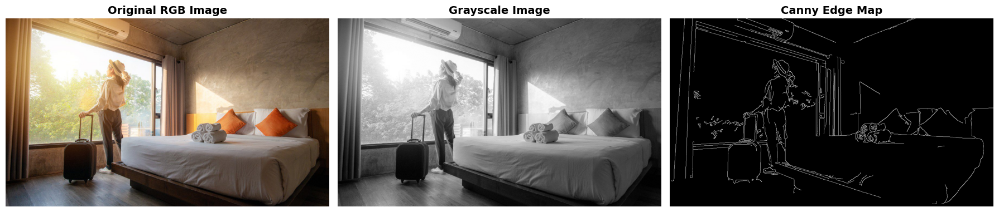

In [10]:
# Display the input images
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(rgb_img)
axes[0].set_title('Original RGB Image', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(gray_img, cmap='gray')
axes[1].set_title('Grayscale Image', fontsize=14, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(edges, cmap='gray')
axes[2].set_title('Canny Edge Map', fontsize=14, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## 10. Run All 4 Segmentation Approaches

**Note**: Implement the 4 approaches in Section 5 before running this cell.

In [21]:
# # Uncomment and run after implementing the 4 approaches
# 
# # Run all 4 approaches
results = []

print("Running segmentation approaches...\n")

# Approach 1
start_time = time.time()
result1 = segment_regions_approach_1(gray_img, edges, MIN_REGION_AREA)
result1['processing_time'] = time.time() - start_time
results.append(result1)
print(f"Approach 1: {result1['num_regions']} regions in {result1['processing_time']:.3f}s")

# Approach 2
start_time = time.time()
result2 = segment_regions_approach_2(rgb_img, edges, MIN_REGION_AREA)
result2['processing_time'] = time.time() - start_time
results.append(result2)
print(f"Approach 2: {result2['num_regions']} regions in {result2['processing_time']:.3f}s")

# Approach 3
start_time = time.time()
result3 = segment_regions_approach_3(gray_img, edges, MIN_REGION_AREA)
result3['processing_time'] = time.time() - start_time
results.append(result3)
print(f"Approach 3: {result3['num_regions']} regions in {result3['processing_time']:.3f}s")

# Approach 4
start_time = time.time()
result4 = segment_regions_approach_4(rgb_img, edges, MIN_REGION_AREA)
result4['processing_time'] = time.time() - start_time
results.append(result4)
print(f"Approach 4: {result4['num_regions']} regions in {result4['processing_time']:.3f}s")

print("\nAll approaches completed!")

Running segmentation approaches...

Approach 1: 3 regions in 0.094s
Approach 2: 1 regions in 0.008s
Approach 3: 20 regions in 0.067s


error: OpenCV(4.12.0) /Users/xperience/GHA-Actions-OpenCV/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/color.simd_helpers.hpp:92: error: (-15:Bad number of channels) in function 'cv::impl::(anonymous namespace)::CvtHelper<cv::impl::(anonymous namespace)::Set<1>, cv::impl::(anonymous namespace)::Set<3, 4>, cv::impl::(anonymous namespace)::Set<0, 2, 5>>::CvtHelper(InputArray, OutputArray, int) [VScn = cv::impl::(anonymous namespace)::Set<1>, VDcn = cv::impl::(anonymous namespace)::Set<3, 4>, VDepth = cv::impl::(anonymous namespace)::Set<0, 2, 5>, sizePolicy = cv::impl::(anonymous namespace)::NONE]'
> Invalid number of channels in input image:
>     'VScn::contains(scn)'
> where
>     'scn' is 3


## 11. Visualize Comparison

In [20]:
# Uncomment after running Section 10

# Create comparison visualization
fig = create_segmentation_comparison_grid(
    rgb_image=rgb_img,
    grayscale_img=gray_img,
    edge_map=edges,
    results_list=results,
    figsize=(200, 100)
)

plt.show()

# Optionally save the comparison
# output_path = os.path.join(OUTPUT_DIR, f"{test_image_name}_comparison.png")
# fig.savefig(output_path, dpi=150, bbox_inches='tight')
# print(f"Saved comparison to: {output_path}")

Found 3 unique classes: [1 2 3]
Class 1: RGB(31, 119, 180)
Class 2: RGB(140, 86, 75)
Class 3: RGB(23, 190, 207)
Found 1 unique classes: [1]
Class 1: RGB(31, 119, 180)
Found 20 unique classes: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
Class 1: RGB(31, 119, 180)
Class 2: RGB(31, 119, 180)
Class 3: RGB(255, 127, 14)
Class 4: RGB(255, 127, 14)
Class 5: RGB(44, 160, 44)
Class 6: RGB(44, 160, 44)
Class 7: RGB(214, 39, 40)
Class 8: RGB(214, 39, 40)
Class 9: RGB(148, 103, 189)
Class 10: RGB(148, 103, 189)
Class 11: RGB(140, 86, 75)
Class 12: RGB(140, 86, 75)
Class 13: RGB(227, 119, 194)
Class 14: RGB(227, 119, 194)
Class 15: RGB(127, 127, 127)
Class 16: RGB(127, 127, 127)
Class 17: RGB(188, 189, 34)
Class 18: RGB(188, 189, 34)
Class 19: RGB(23, 190, 207)
Class 20: RGB(23, 190, 207)


/var/folders/wj/47jmz7gj0gj8fjfh01t9pkkr0000gp/T/ipykernel_79954/2932419435.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(colormap)


Found 1 unique classes: [1]
Class 1: RGB(31, 119, 180)


## 12. Statistics Summary

In [13]:
# # Uncomment after running Section 10
# 
# import pandas as pd
# 
# # Create summary table
# summary_data = []
# for result in results:
#     summary_data.append({
#         'Method': result['method_name'],
#         'Num Regions': result['num_regions'],
#         'Processing Time (s)': f"{result['processing_time']:.4f}",
#         'Avg Region Size': f"{np.mean([stats['area'] for stats in result['region_stats'].values()]):.1f}" if result['region_stats'] else 'N/A'
#     })
# 
# df = pd.DataFrame(summary_data)
# print("\n=== Segmentation Comparison Summary ===")
# print(df.to_string(index=False))

In [24]:
# Row 2: Segmentation results
for idx, result in enumerate(results):
    col_idx = idx
    
    # Create colored visualization
    viz = overlay_multiclass_mask_on_image(
        rgb_image=rgb_img,
        mask_array=result['labeled_image'],
        background_ind=0,
        opacity=0.5,
        overlay_alpha=0.7,
        colormap='tab10'
    )

    plt.show(viz['image'])
    break

Found 3 unique classes: [1 2 3]
Class 1: RGB(31, 119, 180)
Class 2: RGB(140, 86, 75)
Class 3: RGB(23, 190, 207)


/var/folders/wj/47jmz7gj0gj8fjfh01t9pkkr0000gp/T/ipykernel_79954/2932419435.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(colormap)


# Watershed Segmentation Using Canny Edges - Step by Step Guide

## Overview

This guide implements watershed segmentation using your existing Canny edge detection output. The approach uses distance transform to create a "topographic landscape" where region centers are peaks and edges are valleys. Watershed then floods this landscape to create region boundaries.

**Key Concept**: Distance transform measures how far each pixel is from the nearest edge. Pixels in the center of regions have high distance values (peaks), while edge pixels have zero distance (valleys).

---

## Step 1: Load and Prepare Images

**What happens here**: We load the original RGB image and the Canny edge detection output you already have. We'll also create a grayscale version for later use.

**Expected input**: 
- Original RGB image of the hotel room
- Binary Canny edge map (edges are white 255, background is black 0)

**Expected output**: Three images loaded into memory

In [ ]:
# Step 1: Verify images are loaded and prepare for watershed
print("Step 1: Load and Prepare Images")
print("=" * 50)

# We already have these from Section 8:
# - rgb_img: Original RGB image
# - gray_img: Grayscale version
# - edges: Canny edge map

# Verify shapes
print(f"RGB image shape: {rgb_img.shape}")
print(f"Grayscale image shape: {gray_img.shape}")
print(f"Canny edges shape: {edges.shape}")

# Ensure edges are binary (0 and 255)
_, canny_binary = cv2.threshold(edges, 127, 255, cv2.THRESH_BINARY)

# Check edge statistics
num_edge_pixels = np.count_nonzero(canny_binary)
total_pixels = canny_binary.shape[0] * canny_binary.shape[1]
edge_percentage = (num_edge_pixels / total_pixels) * 100

print(f"\nEdge statistics:")
print(f"  Edge pixels: {num_edge_pixels:,}")
print(f"  Total pixels: {total_pixels:,}")
print(f"  Edge percentage: {edge_percentage:.2f}%")
print(f"  Min value: {canny_binary.min()}, Max value: {canny_binary.max()}")
print("\n✓ Images loaded and prepared successfully!")

In [ ]:
# Step 1: Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(rgb_img)
axes[0].set_title('Original RGB Image', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(gray_img, cmap='gray')
axes[1].set_title('Grayscale Version', fontsize=14, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(canny_binary, cmap='gray')
axes[2].set_title('Canny Edge Map (Binary)', fontsize=14, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

print("✓ Check: Edges should be white (255), background black (0)")
print("✓ Check: Edges should be reasonably complete around major objects")

## Step 2: Invert the Edge Map

**What happens here**: We invert the Canny edge map so that regions (where we want to segment) become white, and edges become black barriers.

**Why this matters**: Distance transform measures distance to nearest black pixel. By making edges black, the distance transform will measure how far each pixel is from an edge - giving us high values at region centers.

**Expected input**: Binary Canny edge map (edges white, background black)

**Expected output**: Inverted binary image (regions white, edges black)

### Pseudo Code

```pseudo
# Invert the edge map
inverted_edges = bitwise_not(canny_binary)

# Optional: Close small gaps in edges
# This helps if your edges have tiny 1-2 pixel breaks
kernel = create_morphology_kernel(shape=ELLIPSE, size=3x3)
closed_edges = morphological_close(inverted_edges, kernel=kernel, iterations=1)
```

### Visualization Instructions

**Display 2 images side by side:**
1. Original Canny edges (edges white)
2. Inverted edges (regions white, edges black)

**What to check**:
- Regions between edges should now be white
- Edges should now be black
- White regions should be the areas you want to segment (bed, window view, walls, etc.)
- If you applied morphological closing, check that small gaps are filled but distinct regions remain separate

**Tip**: If regions look fragmented with many small white patches, you may need stronger morphological closing (larger kernel or more iterations)

---



## Step 3: Compute Distance Transform

**What happens here**: This is the core step. We compute how far each white pixel is from the nearest black (edge) pixel. This creates your "topographic landscape" where region centers become peaks.

**The math**: For each white pixel, find the Euclidean distance to the closest black pixel. Edge pixels get 0, pixels one step away get ~1.0, pixels two steps away get ~1.4 (√2), etc.

**Expected input**: Inverted binary edge map (white regions, black edges)

**Expected output**: Float32 image where values represent distance from edges

### Pseudo Code

```pseudo
# Compute distance transform
# DIST_L2 gives Euclidean distance (most accurate)
# Mask size 5 provides good precision
distance_transform = compute_distance_transform(
    closed_edges, 
    distance_type=DIST_L2, 
    mask_size=5
)

# Normalize for visualization (optional, helps see the landscape)
distance_normalized = normalize(distance_transform, min=0, max=255, type=CV_8U)
```

### Visualization Instructions

**Display 3 images:**
1. Inverted edges (input) - white regions, black edges
2. Distance transform (raw values) - visualize as heatmap/colormap
3. Distance transform normalized (0-255) - easier to see

**What to check**:
- Distance values should be highest at the centers of large regions (bed center, window center)
- Distance should gradually decrease as you move toward edges
- Edge pixels should have distance = 0
- The image should look like a topographic map with peaks at region centers

**Visualization tip**: Use a colormap (like JET or HOT) to display distance transform - warm colors (red/yellow) show high distances (peaks/region centers), cool colors (blue) show low distances (near edges)

**Expected pattern for hotel room**:
- Bright peak in center of bed
- Bright peak in window area
- Bright peak in floor areas between furniture
- Dark valleys along all detected edges

---



## Step 4: Find Markers (Local Maxima)

**What happens here**: We identify peaks in the distance transform - these are region centers that will become watershed markers (flooding sources). Each peak represents one region.

**The logic**: We threshold the distance transform to keep only high-distance pixels (peaks), then label each disconnected peak as a separate marker.

**Expected input**: Distance transform from Step 3

**Expected output**: Binary mask of peak locations, then labeled markers

### Pseudo Code

```pseudo
# Method 1: Simple thresholding
# Keep pixels that are far from edges (e.g., 50% of maximum distance)
max_distance = find_max(distance_transform)
threshold_value = 0.5 * max_distance  # Adjust this ratio to control number of markers

# Create binary mask of peaks
_, peak_mask = threshold(
    distance_transform, 
    threshold_value=threshold_value, 
    max_value=255, 
    type=BINARY
)

# Label each disconnected peak as a unique marker
# connectivity=8 means pixels touching at corners are considered connected
num_labels, markers = connected_components(peak_mask, connectivity=8)

print("Number of markers found:", num_labels - 1)  # -1 because label 0 is background
```

### Visualization Instructions

**Display 4 images in 2x2 grid:**
1. Distance transform (colormap) - to see where peaks are
2. Peak mask (binary) - white spots show where markers will be
3. Markers (labeled) - each marker has unique color/number
4. Original image with markers overlaid - to see what regions they represent

**What to check**:
- Each major region (bed, window, floor sections) should have at least one marker
- Markers should be at region centers, not near edges
- Number of markers = number of regions you expect (roughly)
- If too many markers: increase threshold_value (e.g., 0.6 or 0.7 * max_distance)
- If too few markers: decrease threshold_value (e.g., 0.3 or 0.4 * max_distance)

**Debugging tips**:
- Print the marker counts for each label: `unique_labels, counts = count_unique(markers)`
- Very small marker regions (< 10 pixels) might cause over-segmentation

---



## Step 5: Add Background Marker

**What happens here**: Watershed needs to know which area is "background" versus foreground regions. We add a marker around the image border or in areas we're certain are background.

**Why this matters**: Without a background marker, watershed might merge everything into one region. The background marker acts as a reference point.

**Expected input**: Markers from Step 4

**Expected output**: Markers with background labeled as 1, all other markers incremented

### Pseudo Code

```pseudo
# Create a copy of markers to modify
markers_with_bg = copy(markers)

# Method 1: Use image border as background
# Create a border region (5-10 pixels from edge)
height, width = get_image_size(markers)
border_thickness = 10

# Set all border pixels to 1 (background marker)
markers_with_bg[0:border_thickness, :] = 1  # Top border
markers_with_bg[height-border_thickness:height, :] = 1  # Bottom border
markers_with_bg[:, 0:border_thickness] = 1  # Left border
markers_with_bg[:, width-border_thickness:width] = 1  # Right border

# Increment all other markers by 1 to avoid conflict
# Now background=1, first region=2, second region=3, etc.
markers_with_bg[markers_with_bg > 1] = markers_with_bg[markers_with_bg > 1] + 1

# Convert to int32 (required by watershed)
markers_with_bg = convert_type(markers_with_bg, INT32)
```

### Visualization Instructions

**Display 2 images:**
1. Original markers (before adding background)
2. Markers with background (background should be visible as distinct color around borders)

**What to check**:
- Border pixels should have label = 1 (background)
- Interior region markers should start from label = 2
- No overlap between background marker and region markers
- Print unique marker labels to verify: should see [0, 1, 2, 3, 4, ...] where 0=unlabeled, 1=background, 2+=regions

---



## Step 6: Apply Watershed Algorithm

**What happens here**: This is where the magic happens. Watershed floods from all markers simultaneously on the distance transform landscape. Boundaries form where different floods meet.

**The process**: Imagine each marker is a hole drilled at the bottom of a valley. Water rises uniformly from all holes. When water from two markers is about to merge, a dam (watershed line) is built between them.

**Expected input**: 
- Original RGB image (for display purposes)
- Markers with background (int32 type)

**Expected output**: Modified markers where boundaries = -1, regions keep their labels

### Pseudo Code

```pseudo
# Apply watershed
# IMPORTANT: watershed modifies the markers array in-place
# Pass the original RGB image as first parameter (used for visualization internally)
watershed(original_rgb, markers_with_bg)

# After watershed:
# - Boundaries between regions have value -1
# - Each region keeps its marker label (2, 3, 4, ...)
# - Background keeps label 1

# Create visualization: boundaries in red on original image
result_image = copy(original_rgb)
result_image[markers_with_bg == -1] = [0, 0, 255]  # Set boundary pixels to red (BGR format)
```

### Visualization Instructions

**Display 4 images in 2x2 grid:**
1. Original RGB image
2. Markers before watershed (colored by label)
3. Markers after watershed (colored by label, boundaries should be visible)
4. Result image with red boundaries overlaid on original

**What to check**:
- Red boundary lines (-1) should separate different regions
- Boundaries should roughly align with edges from your Canny detection
- Each region should have a consistent label (same number throughout)
- Boundaries should be continuous lines, not fragmented
- Count regions: `unique_labels = find_unique(markers_with_bg[markers_with_bg > 1])`

**Common issues**:
- If everything is one region: markers weren't distinct enough or background marker missing
- If too fragmented: too many markers in Step 4, increase threshold
- If boundaries don't align with edges: distance transform landscape might need smoothing

---



## Step 7: Extract and Filter Regions

**What happens here**: We extract individual regions from the watershed result, calculate their areas, and filter out small regions below your threshold.

**Expected input**: Watershed result (markers with -1 for boundaries)

**Expected output**: Clean labeled image with only significant regions

### Pseudo Code

```pseudo
# Extract regions (ignore background=1 and boundaries=-1)
regions_only = copy(markers_with_bg)
regions_only[regions_only == -1] = 0  # Remove boundaries
regions_only[regions_only == 1] = 0   # Remove background

# Calculate area (pixel count) for each region
unique_labels, label_counts = count_unique(regions_only, exclude_zero=True)

# Define threshold (e.g., minimum 500 pixels)
area_threshold = 500

# Filter regions by area
filtered_labels = []
for label, count in zip(unique_labels, label_counts):
    if count >= area_threshold:
        filtered_labels.append(label)

# Create final segmentation with only large regions
final_segmentation = zeros_like(regions_only)
for label in filtered_labels:
    final_segmentation[regions_only == label] = label

# Optional: Renumber regions consecutively (1, 2, 3, ...)
final_segmentation = renumber_labels_consecutively(final_segmentation)

print(f"Found {len(filtered_labels)} regions above threshold of {area_threshold} pixels")
```

### Visualization Instructions

**Display 5 images in a grid:**
1. Original RGB image
2. All regions before filtering (colored by label)
3. Region size histogram - bar chart showing pixel count for each region
4. Final segmentation after filtering (colored by label)
5. Original image with final regions overlaid (semi-transparent colored masks)

**What to check**:
- Number of final regions should match major objects in scene
- Small noise regions should be removed
- Region labels should be consecutive: 1, 2, 3, ... N
- Each region should be visually meaningful (bed, window, wall section, etc.)

**For the hotel room, expect regions like**:
- Bed (large region)
- Window/glass area (large region)
- Floor visible in front
- Walls (may be split into multiple sections)
- Ceiling

---



## Step 8: Extract Individual Shapes and Properties

**What happens here**: For each region, we create individual masks and extract properties like area, bounding box, contour, and centroid. These can be saved as separate datatypes.

**Expected input**: Final segmentation from Step 7

**Expected output**: List/dictionary of region objects with properties

### Pseudo Code

```pseudo
# Get list of final region labels
region_labels = find_unique(final_segmentation, exclude_zero=True)

# Storage for region data
regions_data = []

for label in region_labels:
    # Create binary mask for this region
    region_mask = (final_segmentation == label).astype(uint8) * 255
    
    # Calculate properties
    area = count_nonzero(region_mask)
    
    # Find contour
    contours, _ = find_contours(region_mask, mode=EXTERNAL, method=SIMPLE)
    main_contour = contours[0]  # Largest contour
    
    # Get bounding box
    x, y, width, height = bounding_rectangle(main_contour)
    
    # Calculate centroid
    moments = compute_moments(region_mask)
    cx = moments['m10'] / moments['m00']
    cy = moments['m01'] / moments['m00']
    
    # Store region data
    region_info = {
        'label': label,
        'mask': region_mask,
        'contour': main_contour,
        'area': area,
        'bounding_box': (x, y, width, height),
        'centroid': (cx, cy)
    }
    regions_data.append(region_info)

# Save regions (example: save masks as separate images)
for i, region in enumerate(regions_data):
    save_image(f"region_{i+1}_mask.png", region['mask'])
```

### Visualization Instructions

**Display a comprehensive figure with:**
1. Original image with all region contours drawn in different colors
2. Original image with bounding boxes around each region
3. Original image with centroid points marked
4. Grid of individual region masks (NxN subplot of all extracted regions)

**Additional visualization**:
- Create a table/text output showing:
  - Region ID
  - Area (pixels)
  - Bounding box coordinates
  - Centroid coordinates
  - Percentage of total image

**What to check**:
- Each region should have a clean, continuous contour
- Bounding boxes should tightly fit regions
- Centroids should be inside their respective regions
- Masks should be binary (0 and 255 only)

---



## Step 9: Save and Store Region Data

**What happens here**: We save the extracted regions in a structured format that can be loaded later for further processing.

### Pseudo Code

```pseudo
# Option 1: Save as pickle file (Python native)
import pickle
with open('regions_data.pkl', 'wb') as f:
    pickle.dump(regions_data, f)

# Option 2: Save as JSON (more portable, exclude large arrays)
import json
regions_json = []
for region in regions_data:
    region_json = {
        'label': int(region['label']),
        'area': int(region['area']),
        'bounding_box': region['bounding_box'],
        'centroid': region['centroid'],
        'contour_points': region['contour'].tolist()  # Convert numpy array to list
    }
    regions_json.append(region_json)

with open('regions_data.json', 'w') as f:
    json.dump(regions_json, f, indent=2)

# Option 3: Save labeled segmentation as image
# Use colormap for visualization
segmentation_colored = apply_colormap(final_segmentation, colormap=JET)
save_image('final_segmentation.png', segmentation_colored)

# Save the labeled array as numpy file for exact reconstruction
save_numpy('final_segmentation_labels.npy', final_segmentation)
```

### Visualization Instructions

**Final summary visualization**:
Create a single figure with 4 panels showing the complete pipeline:
1. Input: Original RGB image
2. Input: Canny edges
3. Intermediate: Distance transform (colormap)
4. Output: Final segmentation with regions colored

**Also display**:
- Text summary with total regions found, average region size, largest region info

---



## Troubleshooting Guide

### Problem: Too many small regions

**Causes**:
- Threshold in Step 4 too low
- Canny edges too fragmented

**Solutions**:
- Increase `threshold_value` in Step 4 (try 0.6 or 0.7 * max_distance)
- Apply stronger morphological closing in Step 2 (larger kernel or more iterations)
- Increase `area_threshold` in Step 7

### Problem: Too few regions / Everything merges

**Causes**:
- Threshold in Step 4 too high
- Markers not distinct enough

**Solutions**:
- Decrease `threshold_value` in Step 4 (try 0.3 or 0.4 * max_distance)
- Check distance transform visualization - should show clear peaks
- Verify markers are in region centers, not edges

### Problem: Boundaries don't align with edges

**Causes**:
- Distance transform not following Canny edges well
- Canny edges have gaps

**Solutions**:
- Apply morphological closing in Step 2 to fill gaps
- Try smoothing distance transform with Gaussian blur before Step 4
- Verify Canny edges are complete around major objects

### Problem: Regions leak through gaps

**Causes**:
- Canny edges incomplete
- Morphological closing not applied or too weak

**Solutions**:
- Increase kernel size or iterations in morphological closing (Step 2)
- Check Canny edge detection parameters - might need adjustment
- Use watershed's natural gap-closing behavior with appropriate markers

---

## Parameter Summary

Key parameters to adjust for your specific image:

| Step | Parameter | Typical Range | Effect |
|------|-----------|---------------|--------|
| 2 | Morphological kernel size | 3x3 to 7x7 | Larger = close bigger gaps |
| 2 | Closing iterations | 1 to 3 | More = stronger gap closing |
| 4 | Threshold ratio | 0.3 to 0.7 | Higher = fewer markers |
| 4 | Connectivity | 4 or 8 | 8 = more connected markers |
| 5 | Border thickness | 5 to 20 pixels | Adjust based on image size |
| 7 | Area threshold | 100 to 5000 pixels | Minimum region size to keep |

Start with middle values and adjust based on your visualizations!